# Análise Microestrutural: Atividade II

Preparação e análise microestrutural do **aço carbono 1010** (0,10 %p C, microestrutura predominantemente ferrítica) e determinação do **número de tamanho de grão ASTM (G)** segundo a norma ASTM E112, pelo método do intercepto circular, a partir das 5 micrografias obtidas pelo grupo.

**Etapas do roteiro cobertas neste notebook**

| Etapa do roteiro | O que é feito | Seção |
|---|---|---|
| Introdução (eqs. 1 a 3) | Definição de G, $N_L$, $\bar{l}$ e origem das constantes da eq. (3) | 1 |
| 3.2 | Preparação metalográfica e microscopia óptica de luz refletida | 2 |
| 3.3 | Leitura das 5 micrografias e calibração pela barra de escala | 3 |
| 3.3 | Círculo de teste traçado sobre cada região | 4 |
| 3.3 | Contagem do número de grãos interceptados N (com o círculo "desenrolado" em faixas) | 5 |
| 3.3, eqs. (4), (2) e (3) | $N_L$, $\bar{l}$ e G de cada região | 6 |
| Relatório | Todos os cálculos de cada região, passo a passo | 7 |
| Relatório | Valor médio de G e desvio padrão (com IC 95 % e %RA da ASTM E112) | 8 e 9 |
| Discussão | Interpretação, aumentos diferentes entre as fotos e propriedades mecânicas | 10 |
| Anexo | Validação do método numa microestrutura sintética de grãos conhecidos | 12 |

> **Fluxo de uso:** (1) ajuste a pasta das fotos na seção 3; (2) rode até a seção 5 para gerar as fotos com o círculo e as faixas de contagem; (3) conte os cruzamentos, preencha as contagens na seção 5 e rode o notebook inteiro de novo. Enquanto as contagens não forem preenchidas, a execução para na seção 5 com um aviso.

In [69]:
# ---------------------------------------------------------------
# Bibliotecas utilizadas
# ---------------------------------------------------------------
import os                         # montagem dos caminhos e verificação dos arquivos
import numpy as np                # cálculos numéricos (log, π, média, desvio padrão...)
import pandas as pd               # montagem das tabelas de resultados
import matplotlib.pyplot as plt   # gráficos
from PIL import Image, ImageDraw, ImageFont     # leitura das fotos e desenho do círculo
from scipy.ndimage import map_coordinates       # interpolação para "desenrolar" o círculo
from scipy import stats           # valor t de Student para o intervalo de confiança
from IPython.display import display, Markdown   # mostra os cálculos formatados em LaTeX

from IPython.display import Image as IPImage
import io

def mostra_jpeg(im, largura=1400, qualidade=80):
    """Exibe uma imagem PIL reduzida em JPEG (deixa o notebook bem mais leve que PNG)."""
    im = im.copy(); im.thumbnail((largura, 100000))
    buf = io.BytesIO(); im.convert("RGB").save(buf, "JPEG", quality=qualidade)
    display(IPImage(data=buf.getvalue()))


def mosaico(imagens, colunas=3, larg=600):
    """Junta várias imagens PIL num mosaico (colunas × linhas) de largura 'larg' por quadro."""
    ims = [im.resize((larg, int(im.height * larg / im.width))) for im in imagens]
    alt = max(im.height for im in ims); linhas = -(-len(ims) // colunas)
    tela = Image.new("RGB", (colunas * larg, linhas * alt), "white")
    for k, im in enumerate(ims):
        tela.paste(im, ((k % colunas) * larg, (k // colunas) * alt))
    return tela

# Faz os gráficos aparecerem dentro do próprio notebook, logo abaixo da célula
%matplotlib inline

## 1. Fundamentos: o número de tamanho de grão ASTM

### Por que medir o tamanho de grão

Um metal policristalino é formado por muitos cristais (**grãos**) com orientações diferentes, separados por **contornos de grão**. Os contornos são barreiras ao movimento das discordâncias: ao chegar a um contorno, a discordância precisa mudar de direção de deslizamento, porque o grão vizinho tem outra orientação. Quanto **menor** o grão, **mais** contornos por unidade de volume e mais difícil a deformação plástica. Por isso, grãos finos aumentam o limite de escoamento, o limite de resistência e a dureza; grãos grosseiros favorecem a ductilidade (Callister, seção 7.8). Essa dependência é descrita pela **equação de Hall-Petch**:

$$\sigma_e = \sigma_0 + k_e\, d^{-1/2}$$

em que $\sigma_e$ é o limite de escoamento, $d$ o diâmetro médio de grão e $\sigma_0$, $k_e$ constantes do material.

### Equação (1): definição de G

A norma ASTM E112 define o número de tamanho de grão G a partir do número **n** de grãos por polegada quadrada numa imagem com aumento de **100×**:

$$n = 2^{\,G-1} \tag{1}$$

Cada unidade a mais em G **dobra** o número de grãos por área. Portanto, **G maior significa grão menor**.

### Equação (2): comprimento de intercepto linear

No método do intercepto, uma linha de teste (reta ou círculo) é traçada sobre a microestrutura e conta-se quantos grãos ela atravessa (**N**) ou quantas vezes ela cruza um contorno (**P**). Dividindo pela extensão **real** da linha obtém-se $N_L$ ou $P_L$ (interseções por mm). O inverso é o **comprimento de intercepto linear médio**:

$$\bar{l} = \frac{1}{N_L} = \frac{1}{P_L} \tag{2}$$

$\bar{l}$ é o comprimento médio do trecho de linha que fica dentro de um grão. Ele **não é** o diâmetro do grão: como a linha corta os grãos em posições aleatórias (nem sempre pelo centro), $\bar{l}$ é menor que o diâmetro.

> Num **círculo** a linha é fechada, não há pontas soltas, e cada contorno cruzado separa dois grãos consecutivos. Por isso, no círculo, **N = P**.

### Equação (3): relação entre G e $\bar{l}$

$$G = -6{,}644\,\log \bar{l} - 3{,}288 \qquad (\bar{l} \text{ em mm}) \tag{3}$$

**De onde vêm as constantes.** Na escala de 100×, a ASTM E112 escreve $G = 10{,}00 - 2\log_2 \bar{l}_{100\times}$. Passando para o tamanho real ($\bar{l}_{100\times} = 100\,\bar{l}$) e para o logaritmo decimal ($\log_2 x = \log x / \log 2$):

$$G = 10 - \frac{2}{\log 2}\left(\log \bar{l} + 2\right) = -\frac{2}{\log 2}\log\bar{l} + \left(10 - \frac{4}{\log 2}\right)$$

Como $2/\log 2 = 6{,}644$ e $10 - 4/\log 2 = -3{,}288$, chega-se à eq. (3). O coeficiente 2 aparece porque $\bar{l}$ é um comprimento, enquanto $n$ conta grãos por **área**: dobrar $n$ equivale a dividir $\bar{l}$ por $\sqrt{2}$. A célula abaixo confere as constantes.

In [70]:
# Conferência numérica das constantes da equação (3)
coef = 2 / np.log10(2)            # coeficiente angular: 2/log(2)
const = 10 - 4 / np.log10(2)      # termo independente: 10 - 4/log(2)
print(f"2/log 2      = {coef:.4f}   (roteiro: 6,644)")
print(f"10 - 4/log 2 = {const:.4f}  (roteiro: -3,288)")

2/log 2      = 6.6439   (roteiro: 6,644)
10 - 4/log 2 = -3.2877  (roteiro: -3,288)


## 2. Preparação metalográfica e microscopia (seção 3.2)

O objetivo da preparação é obter uma superfície **plana, sem riscos e sem deformação**, e depois revelar os contornos de grão.

| Etapa | O que é feito | Por quê |
|---|---|---|
| a) Corte | Cortadeira *cut-off* com disco abrasivo e refrigeração | Retirar uma seção representativa sem aquecer a amostra (o calor pode alterar a microestrutura) |
| b) Embutimento | Baquelite em embutidora a quente | Facilitar o manuseio e manter as bordas planas durante o lixamento |
| c) Lixamento | Lixas de SiC, granas 220 → 320 → 400 → 600 | Cada lixa remove os riscos da anterior; gira-se a amostra 90° a cada troca para ver quando os riscos antigos sumiram |
| d) Polimento | Pano de feltro com alumina de 1 µm | Remover os riscos finos e deixar a superfície espelhada |
| e) Ataque químico | Imersão em Nital 3 % (HNO₃ em álcool etílico) | Corroer preferencialmente os contornos de grão, que têm maior energia |

**Por que os contornos aparecem escuros.** No microscópio óptico de **luz refletida** a luz incide perpendicularmente à superfície. O interior do grão polido reflete a luz de volta para a objetiva e aparece claro. O ataque abre pequenos sulcos nos contornos; nesses sulcos a superfície fica inclinada, a luz é refletida para fora da objetiva e o contorno aparece como uma **linha escura**. Sem o ataque, uma amostra polida de ferrita aparece uniformemente clara e os grãos não são vistos.

**Aço 1010.** Com 0,10 %p C, a microestrutura é quase toda **ferrita** (grãos claros e poligonais), com pouca **perlita** (regiões escuras, em geral nos contornos). Na contagem, as colônias de perlita são tratadas como grãos.

## 3. Micrografias e calibração pela barra de escala (seção 3.3)

O cálculo do tamanho de grão precisa do **comprimento real** da linha de teste sobre a amostra. Numa foto digital, isso vem da **barra de escala** gravada pelo software do microscópio: medindo o comprimento da barra em pixels, obtém-se quantos micrômetros cada pixel representa:

$$\text{µm/pixel} = \frac{\text{comprimento real da barra (µm)}}{\text{comprimento da barra na imagem (pixels)}}$$

A função `mede_barra` encontra a barra automaticamente: ela procura, no quadrante inferior direito da foto, a linha horizontal escura contínua mais longa. Se a detecção falhar em alguma foto, informe o comprimento em pixels manualmente em `BARRA_PX_MANUAL`.

> **As 5 fotos não têm o mesmo aumento.** As barras de 50 µm medem 145, 731, 731, 364 e 364 pixels, numa proporção de 1 : 2,5 : 5. Isso indica objetivas de 20×, 50× e 100× (com ocular de 10×, **200×, 500× e 1000×**). O aumento nominal está em `AUMENTO_NOMINAL` só para registro: confirmem com as anotações da aula. **O cálculo não depende dele**, porque usa a barra de escala de cada foto.

In [71]:
# Pasta e nomes das 5 fotos (ajuste para o seu computador)
PASTA_FOTOS = r"C:\Users\bruno\OneDrive\Visual Studio Code\2026.3\Materiais e suas Propriedades\Laboratório 02"
FOTOS = ["1 - Longitudinal 50X.jpg", "2 - Transversal 50X.jpg", "3 - Longitudinal 100X.jpg", "4 - Transversal 100X.jpg", "5 - Longitudinal 20X.jpg"]

BARRA_UM = 50                 # valor escrito na barra de escala de todas as fotos (µm)
BARRA_PX_MANUAL = {}          # Ex.: {2: 731} para forçar o comprimento da barra da região 2 (pixels)
AUMENTO_NOMINAL = [500, 500, 1000, 1000, 200]   # aumento total (objetiva × ocular 10×)

regioes = [os.path.splitext(f)[0] for f in FOTOS]   # Ex.: "1 - Longitudinal 50X"

In [72]:
def fonte(tamanho):
    """Fonte em negrito para os rótulos (tenta Arial no Windows e DejaVu no Linux)."""
    for nome in ("arialbd.ttf", "DejaVuSans-Bold.ttf", "/usr/share/fonts/truetype/dejavu/DejaVuSans-Bold.ttf"):
        try:
            return ImageFont.truetype(nome, tamanho)
        except OSError:
            pass
    return ImageFont.load_default()


def mede_barra(rgb):
    """
    Mede o comprimento (em pixels) da barra de escala: procura, no quadrante inferior
    direito, a linha com o maior trecho contínuo de pixels pretos.
    Retorna (comprimento, linha, x_inicial, x_final).
    """
    h, w, _ = rgb.shape
    escuro = rgb.astype(int).sum(axis=2) < 150          # pixel quase preto (R+G+B < 150)
    melhor = (0, 0, 0, 0)
    for lin in range(int(0.6 * h), h):                  # só os 40 % de baixo da imagem
        trecho = escuro[lin, w // 2:].astype(int)       # só a metade direita
        borda = np.diff(np.r_[0, trecho, 0])            # +1 onde começa um trecho, -1 onde termina
        ini, fim = np.where(borda == 1)[0], np.where(borda == -1)[0]
        if len(ini):
            k = np.argmax(fim - ini)                    # trecho mais longo desta linha
            if fim[k] - ini[k] > melhor[0]:
                melhor = (fim[k] - ini[k], lin, ini[k] + w // 2, fim[k] + w // 2)
    return melhor


fotos, calib = [], []
for i, arq in enumerate(FOTOS, start=1):
    rgb = np.asarray(Image.open(os.path.join(PASTA_FOTOS, arq)).convert("RGB"))
    fotos.append(rgb)
    barra_px, lin, x0, x1 = mede_barra(rgb)
    barra_px = BARRA_PX_MANUAL.get(i, barra_px)          # valor manual, se informado
    um_px = BARRA_UM / barra_px                          # calibração (µm por pixel)
    h, w, _ = rgb.shape
    calib.append({"Arquivo": arq, "Imagem (px)": f"{w} × {h}", "Barra (px)": barra_px,
                  "µm/pixel": round(um_px, 4),
                  "Campo (µm)": f"{w*um_px:.0f} × {h*um_px:.0f}",
                  "Aumento nominal": f"{AUMENTO_NOMINAL[i-1]}×"})

calibracao = pd.DataFrame(calib, index=regioes)
UM_PX = calibracao["µm/pixel"].to_numpy()
calibracao

,Arquivo,Imagem (px),Barra (px),µm/pixel,Campo (µm),Aumento nominal
1 - Longitudinal 50X,1 - Longitudinal 50X.jpg,2452 × 2056,364,0.1374,337 × 282,500×
2 - Transversal 50X,2 - Transversal 50X.jpg,2452 × 2056,364,0.1374,337 × 282,500×
3 - Longitudinal 100X,3 - Longitudinal 100X.jpg,2452 × 2056,731,0.0684,168 × 141,1000×
4 - Transversal 100X,4 - Transversal 100X.jpg,2452 × 2056,731,0.0684,168 × 141,1000×
5 - Longitudinal 20X,5 - Longitudinal 20X.jpg,2452 × 2056,145,0.3448,846 × 709,200×


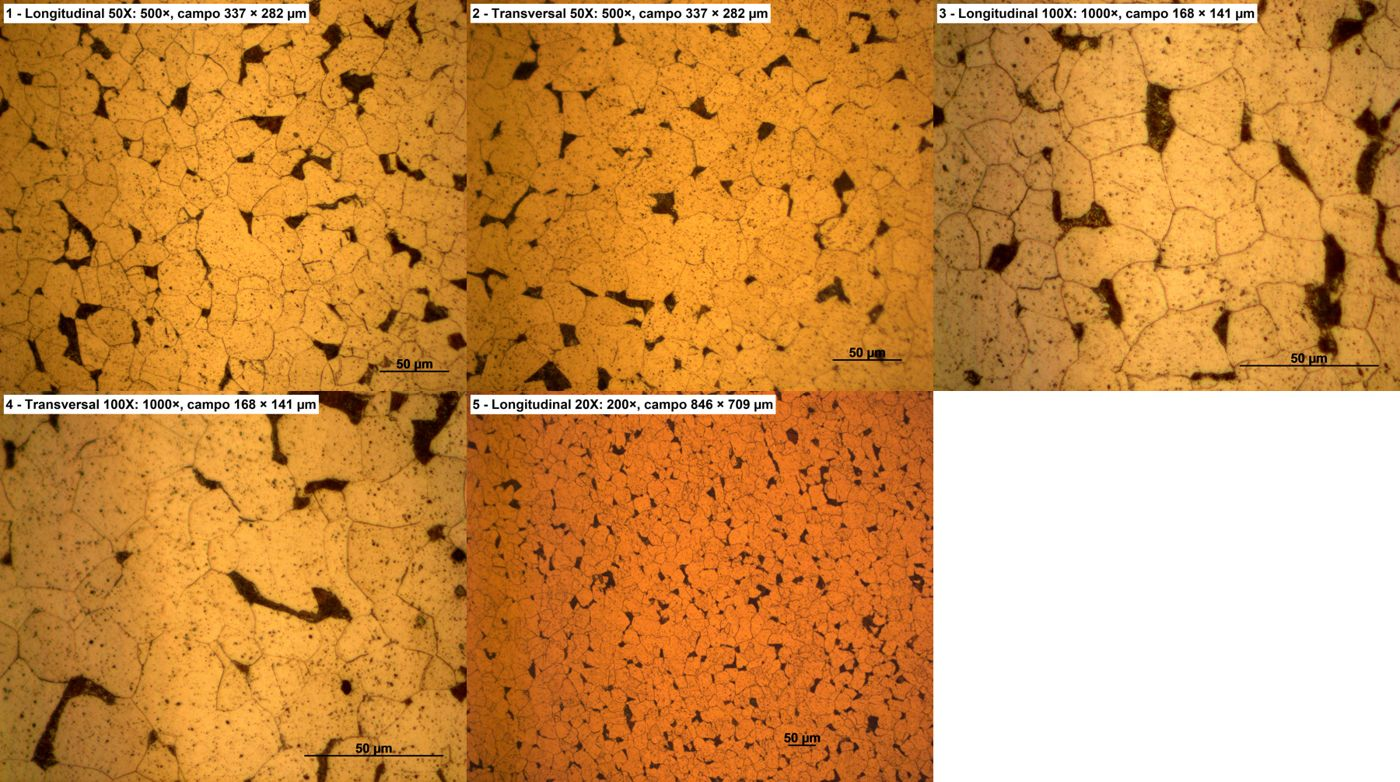

In [73]:
# Mostra as 5 micrografias lado a lado, com o nome, o aumento e o campo de visão real
quadros = []
for rgb, nome, (_, lin) in zip(fotos, regioes, calibracao.iterrows()):
    im = Image.fromarray(rgb).copy()
    d = ImageDraw.Draw(im); f = fonte(70)
    txt = f"{nome}: {lin['Aumento nominal']}, campo {lin['Campo (µm)']} µm"
    bb = d.textbbox((30, 30), txt, font=f)
    d.rectangle([20, 20, bb[2] + 12, bb[3] + 12], fill="white"); d.text((30, 30), txt, fill="black", font=f)
    quadros.append(im)
mostra_jpeg(mosaico(quadros))

## 4. Círculo de teste sobre cada região (seção 3.3)

### Do círculo de 100 mm ao diâmetro real

O roteiro pede um círculo de **D = 100 mm** sobre a foto impressa em **M = 200×**. O que de fato entra no cálculo é o tamanho do círculo **sobre a amostra**:

$$D_{real} = \frac{D}{M} = \frac{100 \text{ mm}}{200} = 0{,}5 \text{ mm} = 500 \text{ µm}$$

Substituindo na eq. (4), ela fica escrita só com grandezas reais:

$$N_L = \frac{N}{\pi D}\cdot M = \frac{N}{\pi\,(D/M)} = \frac{N}{\pi D_{real}}$$

Assim, numa foto digital calibrada, basta desenhar um círculo de diâmetro real conhecido e dividir N pelo seu perímetro real.

### Tamanho do círculo em cada foto

- **Região 1 (200×):** o campo tem 846 × 709 µm, então cabe o círculo do roteiro, de **500 µm**.
- **Regiões 4 e 5 (500×)** e **regiões 2 e 3 (1000×):** o campo é menor que 500 µm. Usa-se o maior diâmetro "redondo" que caiba com folga (90 % da menor dimensão): **250 µm** e **125 µm**.

As marcas de 0° a 315° dividem o círculo em 8 setores para organizar a contagem. O círculo é desenhado na resolução original da foto e salvo como `regiao_<n>_circulo.jpg` para o relatório.

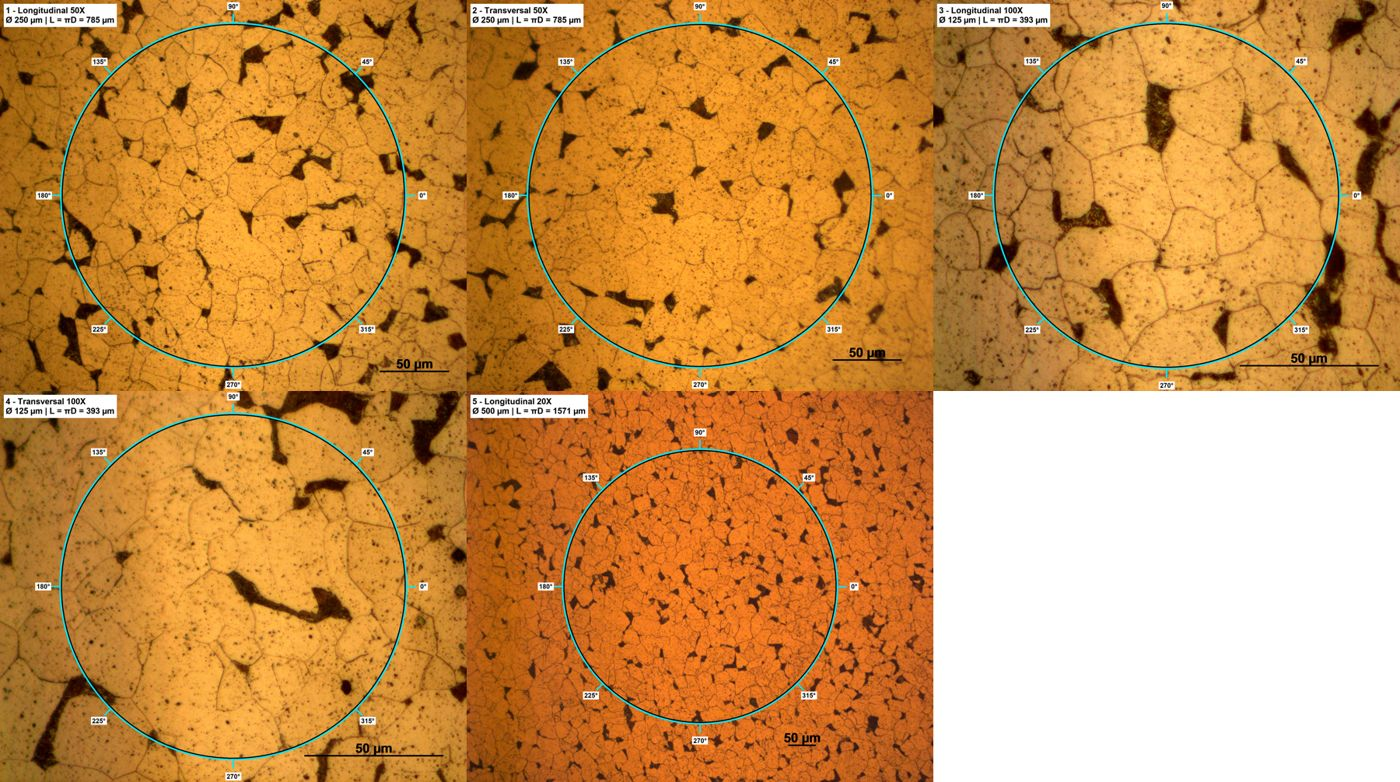

,D real (µm),L = πD real (µm)
1 - Longitudinal 50X,250,785.4
2 - Transversal 50X,250,785.4
3 - Longitudinal 100X,125,392.7
4 - Transversal 100X,125,392.7
5 - Longitudinal 20X,500,1570.8


In [74]:
DIAMETROS_UM = [500, 400, 300, 250, 200, 150, 125, 100, 75, 50]   # opções "redondas" (µm)

def escolhe_diametro(rgb, um_px, folga=0.9):
    """Maior diâmetro da lista que cabe em 90 % da menor dimensão da foto."""
    menor_dim_um = min(rgb.shape[:2]) * um_px
    return next(d for d in DIAMETROS_UM if d <= folga * menor_dim_um)


def desenha_circulo(rgb, um_px, d_um, titulo, setores=8):
    """
    Desenha o círculo de diâmetro real d_um (µm) no centro da foto, com marcas de setor.
    Usa ciano com contorno preto, que contrasta com o fundo laranja da ferrita.
    """
    im = Image.fromarray(rgb).copy()
    w, h = im.size
    cx, cy, r = w / 2, h / 2, d_um / um_px / 2           # centro e raio em pixels
    d = ImageDraw.Draw(im)
    for cor, esp in [((0, 0, 0), 14), ((0, 230, 255), 8)]:   # contorno preto + linha ciano
        d.ellipse([cx - r, cy - r, cx + r, cy + r], outline=cor, width=esp)
    f_set, f_tit = fonte(34), fonte(44)
    for k in range(setores):
        a = np.radians(360 * k / setores)                 # ângulo medido a partir do eixo x, anti-horário
        d.line([cx + r*np.cos(a), cy - r*np.sin(a), cx + (r+45)*np.cos(a), cy - (r+45)*np.sin(a)],
               fill=(0, 230, 255), width=8)
        txt = f"{360*k//setores}°"
        bb = d.textbbox((0, 0), txt, font=f_set); tw, th = bb[2] - bb[0], bb[3] - bb[1]
        tx = min(max(cx + (r+85)*np.cos(a), tw/2 + 8), w - tw/2 - 8)    # mantém o rótulo na imagem
        ty = min(max(cy - (r+85)*np.sin(a), th/2 + 10), h - th/2 - 10)
        d.rectangle([tx - tw/2 - 6, ty - th/2 - 8, tx + tw/2 + 6, ty + th/2 + 8], fill="white")
        d.text((tx - tw/2, ty - th/2 - bb[1]), txt, fill="black", font=f_set)
    txt = f"{titulo}\nØ {d_um} µm | L = πD = {np.pi*d_um:.0f} µm"
    bb = d.multiline_textbbox((30, 30), txt, font=f_tit, spacing=10)
    d.rectangle([20, 20, bb[2] + 12, bb[3] + 12], fill="white")
    d.multiline_text((30, 30), txt, fill="black", font=f_tit, spacing=10)
    return im


D_REAL_UM, com_circulo = [], []
for i, (rgb, um_px, nome) in enumerate(zip(fotos, UM_PX, regioes), start=1):
    d_um = escolhe_diametro(rgb, um_px)
    D_REAL_UM.append(d_um)
    im = desenha_circulo(rgb, um_px, d_um, nome)
    im.save(f"regiao_{i}_circulo.jpg", quality=92)       # figura em resolução original (relatório)
    com_circulo.append(im)
mostra_jpeg(mosaico(com_circulo))

D_REAL_MM = np.array(D_REAL_UM) / 1000                    # diâmetros reais (mm)
L_REAL_MM = np.pi * D_REAL_MM                             # comprimento real de cada linha de teste (mm)
pd.DataFrame({"D real (µm)": D_REAL_UM, "L = πD real (µm)": (L_REAL_MM * 1000).round(1)}, index=regioes)

## 5. Contagem dos grãos interceptados (Seção 3.3)

### O círculo "desenrolado"

Contar cruzamentos ao longo de um círculo inteiro é fácil de errar: perde-se o ponto de partida ou conta-se um contorno duas vezes. Para facilitar, a função `desenrola_circulo` "abre" uma faixa estreita ao redor do círculo e a transforma numa **tira reta**, dividida nos mesmos 8 setores das marcas de 0° a 315°. Nas tiras:

- a **linha tracejada** central é o círculo de teste;
- cada contorno de grão aparece como uma linha escura que **atravessa a linha tracejada**;
- a leitura é da **esquerda para a direita**, no sentido anti-horário do círculo;
- a faixa acima da linha é o lado de **fora** do círculo, e a de baixo é o lado de **dentro**.

As tiras são salvas como `regiao_<n>_faixas.jpg`. Abram em tela cheia para contar.

### Regras de contagem (ASTM E112)

- conte cada vez que a linha tracejada **cruza um contorno** (no círculo, N = P);
- **tangente** a um contorno: conte **1**;
- passagem exatamente por um **ponto triplo**: conte **1,5** (a norma aceita 2 na contagem com círculo);
- **perlita** (regiões escuras): cada colônia conta como um grão. Entrar nela é um cruzamento e sair é outro, então uma colônia atravessada conta **2**;
- **pites e inclusões** (pontos escuros isolados dentro dos grãos) **não** são contornos e **não** contam;
- um contorno que cai exatamente na **divisa entre dois setores** deve ser contado em apenas um deles.

In [75]:
def desenrola_circulo(rgb, um_px, d_um, meia_faixa=0.06, setores=8, largura=1400):
    """
    "Desenrola" uma faixa de ±(meia_faixa·D) em torno do círculo numa imagem reta.
    Cada setor de 360°/setores vira uma tira de 'largura' pixels, com a linha do círculo tracejada.
    """
    h, w, _ = rgb.shape
    cx, cy, r = w / 2, h / 2, d_um / um_px / 2
    n = int(round(2 * np.pi * r))                         # 1 amostra por pixel de perímetro
    meia = int(meia_faixa * d_um / um_px)                 # meia altura da faixa (pixels)
    t = np.arange(n) / n * 2 * np.pi                      # ângulo de cada amostra (anti-horário)
    R = r + np.arange(meia, -meia - 1, -1)[:, None]       # de fora (topo) para dentro (base)
    X, Y = cx + R * np.cos(t)[None], cy - R * np.sin(t)[None]
    faixa = np.stack([map_coordinates(rgb[..., c].astype(float), [Y, X], order=1)
                      for c in range(3)], axis=-1).clip(0, 255).astype(np.uint8)

    passo, f = n // setores, fonte(22)
    blocos = []
    for k in range(setores):
        tira = Image.fromarray(faixa[:, k*passo:(k+1)*passo])
        tira = tira.resize((largura, max(60, int(tira.height * largura / tira.width))))
        d = ImageDraw.Draw(tira); ym = tira.height // 2
        for x in range(0, largura, 6):                    # linha tracejada = círculo de teste
            d.line([x, ym, x + 3, ym], fill=(0, 200, 255), width=2)
        rot = Image.new("RGB", (largura, 30), "white")
        ImageDraw.Draw(rot).text((5, 3), f"Setor {k+1}: {360*k//setores}° → {360*(k+1)//setores}°"
                                 f"   ({np.pi*d_um/setores:.0f} µm de linha)", fill="black", font=f)
        blocos += [rot, tira]
    saida = Image.new("RGB", (largura, sum(b.height for b in blocos)), "white")
    y = 0
    for b in blocos:
        saida.paste(b, (0, y)); y += b.height
    return saida


for i, (rgb, um_px, d_um) in enumerate(zip(fotos, UM_PX, D_REAL_UM), start=1):
    desenrola_circulo(rgb, um_px, d_um).save(f"regiao_{i}_faixas.jpg", quality=88)
print("Tiras salvas: " + ", ".join(f"regiao_{i}_faixas.jpg" for i in range(1, len(fotos) + 1)))

Tiras salvas: regiao_1_faixas.jpg, regiao_2_faixas.jpg, regiao_3_faixas.jpg, regiao_4_faixas.jpg, regiao_5_faixas.jpg


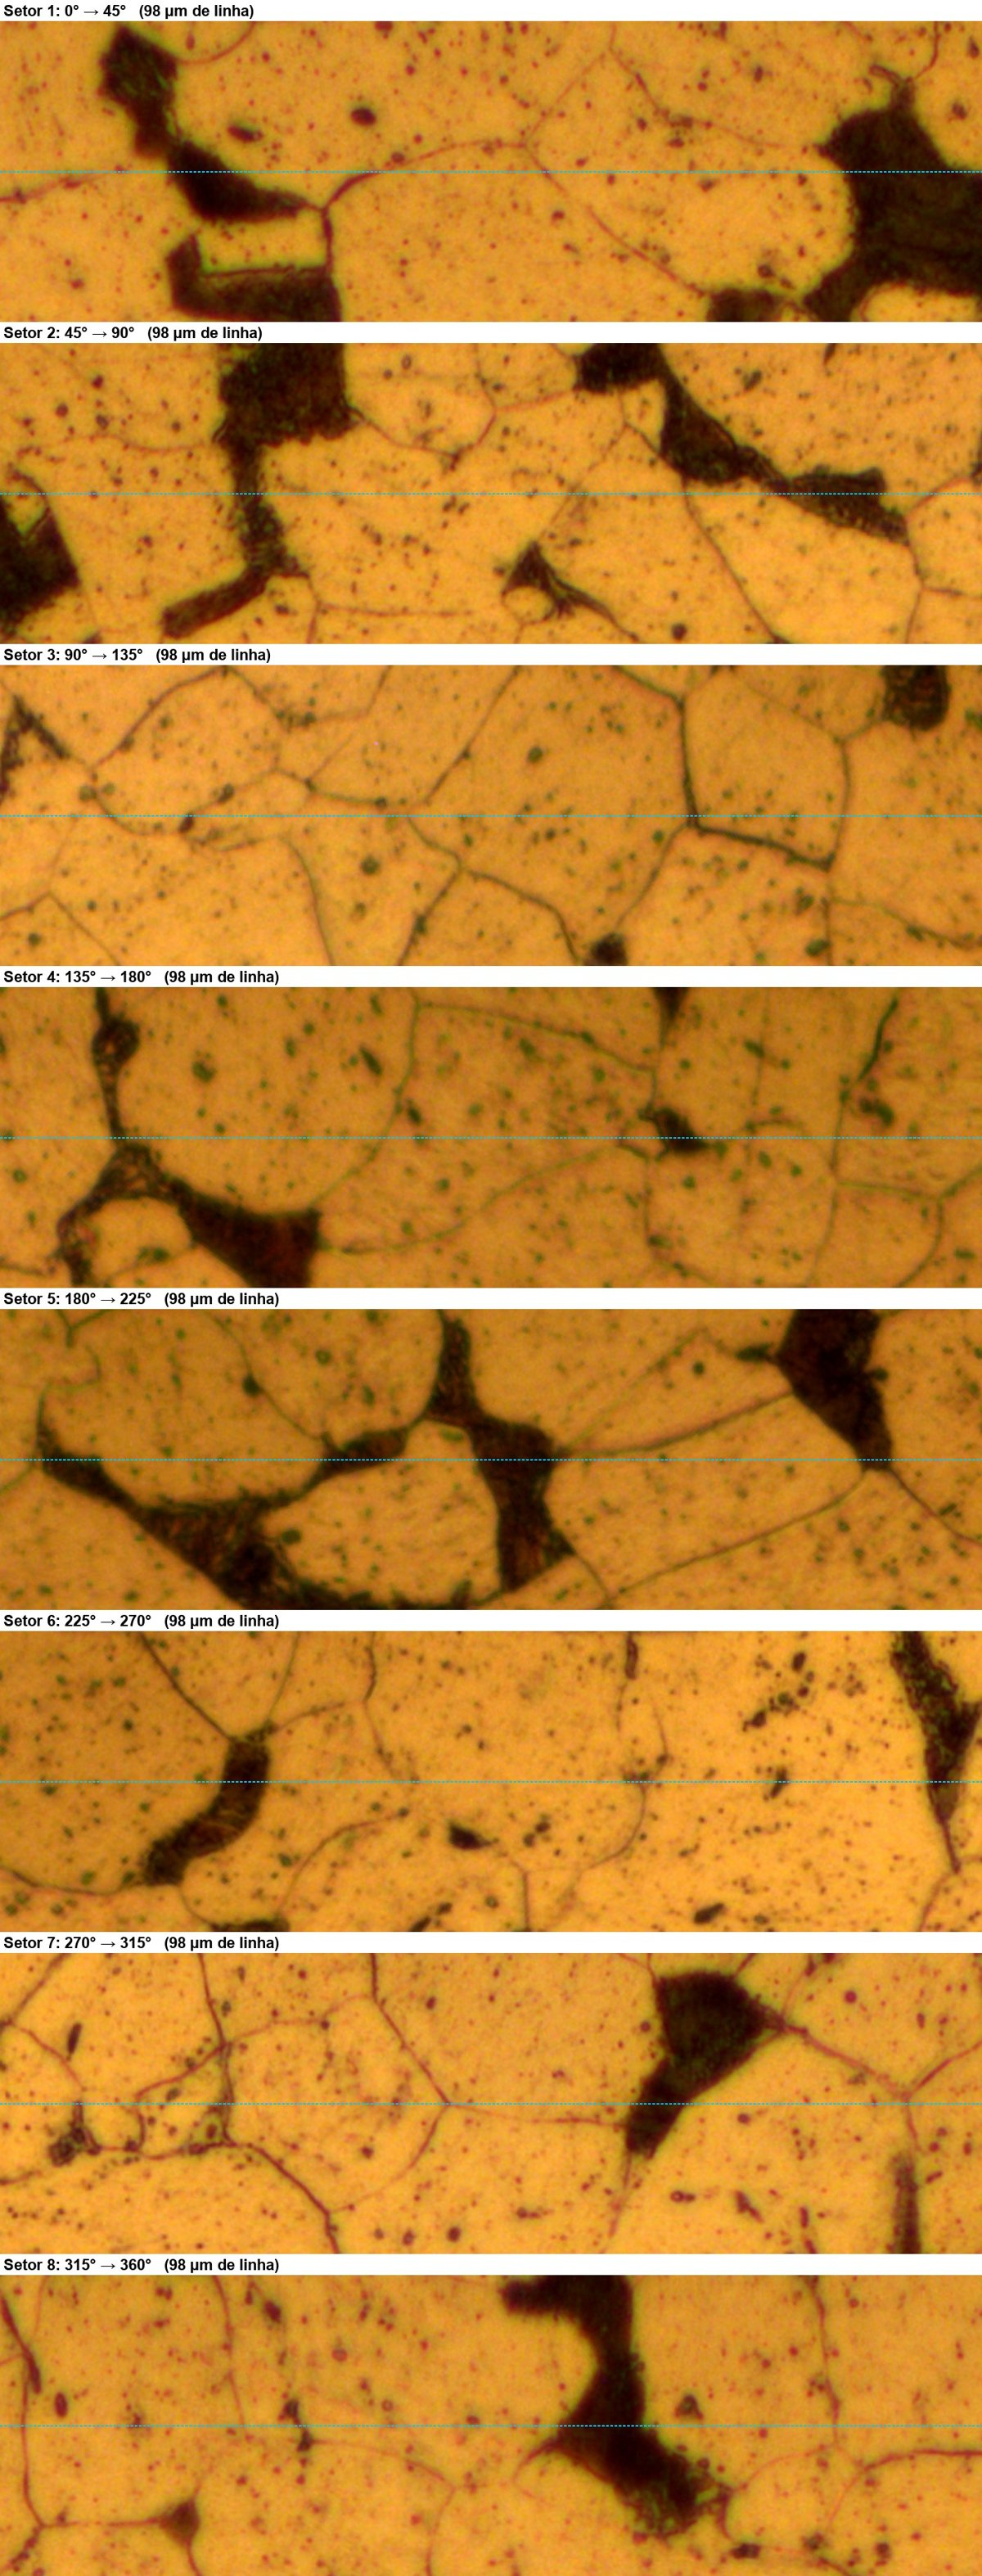

In [76]:
# Exemplo: tiras da Região 1 (troque o número para ver as outras)
REGIAO_VER = 1
mostra_jpeg(Image.open(f"regiao_{REGIAO_VER}_faixas.jpg"), largura=1200, qualidade=85)

### Preenchimento das contagens

Preencha o número de cruzamentos de **cada setor** (8 valores por região). O total N de cada região é a soma dos setores, e a tabela por setor pode ir para o relatório como registro da contagem. Valores com ,5 são permitidos (pontos triplos).

> ⏳ Enquanto houver `None`, a execução **para nesta seção** com um aviso. Depois de preencher, rode o notebook inteiro de novo.

In [77]:
# Cruzamentos por setor (0-45°, 45-90°, ..., 315-360°) em cada região
CONTAGEM_SETORES = {
    1: [7, 8, 6, 9, 8, 7, 9, 5],
    2: [6, 4, 4, 7, 5, 7, 8, 4],
    3: [1, 2, 8, 5, 5, 2, 2, 4],
    4: [4, 2, 3, 1, 4, 4, 1, 4],
    5: [10, 10, 11, 8, 9, 14, 12, 7],
}

class ContagemPendente(Exception):
    """Interrompe a execução sem mostrar o traceback quando faltam contagens."""
    def _render_traceback_(self):
        return ["⏳ Contagem pendente: preencha CONTAGEM_SETORES e rode o notebook de novo."]


faltando = [r for r, v in CONTAGEM_SETORES.items() if any(x is None for x in v)]
if faltando:
    raise ContagemPendente(f"Faltam contagens nas regiões {faltando}")

tabela_setores = pd.DataFrame(CONTAGEM_SETORES, index=[f"{45*k}°–{45*(k+1)}°" for k in range(8)]).T
tabela_setores.index = regioes
tabela_setores["N (total)"] = tabela_setores.sum(axis=1)
N = tabela_setores["N (total)"].to_numpy(dtype=float)
tabela_setores

,0°–45°,45°–90°,90°–135°,135°–180°,180°–225°,225°–270°,270°–315°,315°–360°,N (total)
1 - Longitudinal 50X,7,8,6,9,8,7,9,5,59
2 - Transversal 50X,6,4,4,7,5,7,8,4,45
3 - Longitudinal 100X,1,2,8,5,5,2,2,4,29
4 - Transversal 100X,4,2,3,1,4,4,1,4,23
5 - Longitudinal 20X,10,10,11,8,9,14,12,7,81


## 6. Cálculo de $N_L$, $\bar{l}$ e G para cada região (Seção 3.3)

### Equação (4): Interseções por milímetro

$$N_L = \frac{N}{\pi D}\cdot M = \frac{N}{\pi D_{real}} \tag{4}$$

$\pi D_{real}$ é o comprimento real da linha de teste (seção 4). A unidade de $N_L$ é mm⁻¹.

### Equações (2) e (3)

$$\bar{l} = \frac{1}{N_L} \qquad\qquad G = -6{,}644\,\log \bar{l} - 3{,}288 \quad (\bar{l} \text{ em mm})$$

### Grandezas complementares

A partir de G também se obtêm, pela eq. (1):
- $n = 2^{G-1}$: grãos por polegada quadrada a 100×;
- $N_A = 15{,}50 \cdot 2^{G-1}$: grãos por mm² no tamanho real (o fator 15,50 converte pol² a 100× em mm² a 1×: $100^2 / 645{,}16$);
- $\bar{A} = 1/N_A$: área média de grão.

In [78]:
def calcula_G(N, D_real_mm):
    """Aplica as equações (4), (2) e (3) a contagens N feitas em círculos de diâmetro real D_real_mm."""
    N_L = N / (np.pi * D_real_mm)         # Eq. (4): Interseções por mm na amostra
    l = 1 / N_L                           # Eq. (2): Intercepto linear médio (mm)
    G = -6.644 * np.log10(l) - 3.288      # Eq. (3): Número de tamanho de grão ASTM
    return N_L, l, G

N_L, l, G = calcula_G(N, D_REAL_MM)

n_100x = 2 ** (G - 1)          # eq. (1): grãos por pol² a 100×
N_A = 15.50 * n_100x           # grãos por mm² a 1×
A_med = 1 / N_A                # área média de grão (mm²)

tabela = pd.DataFrame({
    "Aumento": [f"{m}×" for m in AUMENTO_NOMINAL],
    "D real (µm)": D_REAL_UM,
    "L real (mm)": L_REAL_MM.round(4),
    "N": N,
    "N_L (mm⁻¹)": N_L.round(2),
    "l (µm)": (l * 1000).round(2),
    "G": G.round(2),
    "n (grãos/pol² a 100×)": n_100x.round(1),
    "N_A (grãos/mm²)": N_A.round(0).astype(int),
    "Área média (µm²)": (A_med * 1e6).round(0).astype(int),
}, index=regioes)
tabela

,Aumento,D real (µm),L real (mm),N,N_L (mm⁻¹),l (µm),G,n (grãos/pol² a 100×),N_A (grãos/mm²),Área média (µm²)
1 - Longitudinal 50X,500×,250,0.7854,59.0,75.12,13.31,9.17,288.9,4478,223
2 - Transversal 50X,500×,250,0.7854,45.0,57.30,17.45,8.39,168.1,2605,384
3 - Longitudinal 100X,1000×,125,0.3927,29.0,73.85,13.54,9.13,279.2,4328,231
4 - Transversal 100X,1000×,125,0.3927,23.0,58.57,17.07,8.46,175.6,2722,367
5 - Longitudinal 20X,200×,500,1.5708,81.0,51.57,19.39,8.09,136.1,2110,474


## 7. Cálculos detalhados de cada região (para o relatório)

O roteiro pede que **todos os cálculos de cada região** apareçam no relatório. A célula abaixo escreve as equações com os números substituídos, com vírgula decimal, prontas para copiar.

In [79]:
def br(valor, casas):
    """Formata um número com vírgula decimal para o LaTeX (ex.: 31,83)."""
    return f"{valor:.{casas}f}".replace(".", "{,}")

for i, nome in enumerate(regioes):
    cN = 1 if N[i] % 1 else 0                     # mostra decimal só se houver ,5
    texto = (
        f"**{nome}** (aumento {AUMENTO_NOMINAL[i]}×, círculo de {D_REAL_UM[i]} µm, N = {br(N[i], cN)})\n\n"
        f"$$N_L = \\frac{{N}}{{\\pi D_{{real}}}} = \\frac{{{br(N[i], cN)}}}"
        f"{{\\pi \\cdot {br(D_REAL_MM[i], 3)}\\ \\text{{mm}}}} = {br(N_L[i], 2)}\\ \\text{{mm}}^{{-1}}$$\n\n"
        f"$$\\bar{{l}} = \\frac{{1}}{{N_L}} = \\frac{{1}}{{{br(N_L[i], 2)}\\ \\text{{mm}}^{{-1}}}} = "
        f"{br(l[i], 5)}\\ \\text{{mm}} = {br(l[i]*1000, 1)}\\ \\mu\\text{{m}}$$\n\n"
        f"$$G = -6{{,}}644 \\cdot \\log({br(l[i], 5)}) - 3{{,}}288 = "
        f"-6{{,}}644 \\cdot ({br(np.log10(l[i]), 4)}) - 3{{,}}288 = \\mathbf{{{br(G[i], 2)}}}$$\n\n---"
    )
    display(Markdown(texto))

**1 - Longitudinal 50X** (aumento 500×, círculo de 250 µm, N = 59)

$$N_L = \frac{N}{\pi D_{real}} = \frac{59}{\pi \cdot 0{,}250\ \text{mm}} = 75{,}12\ \text{mm}^{-1}$$

$$\bar{l} = \frac{1}{N_L} = \frac{1}{75{,}12\ \text{mm}^{-1}} = 0{,}01331\ \text{mm} = 13{,}3\ \mu\text{m}$$

$$G = -6{,}644 \cdot \log(0{,}01331) - 3{,}288 = -6{,}644 \cdot (-1{,}8758) - 3{,}288 = \mathbf{9{,}17}$$

---

**2 - Transversal 50X** (aumento 500×, círculo de 250 µm, N = 45)

$$N_L = \frac{N}{\pi D_{real}} = \frac{45}{\pi \cdot 0{,}250\ \text{mm}} = 57{,}30\ \text{mm}^{-1}$$

$$\bar{l} = \frac{1}{N_L} = \frac{1}{57{,}30\ \text{mm}^{-1}} = 0{,}01745\ \text{mm} = 17{,}5\ \mu\text{m}$$

$$G = -6{,}644 \cdot \log(0{,}01745) - 3{,}288 = -6{,}644 \cdot (-1{,}7581) - 3{,}288 = \mathbf{8{,}39}$$

---

**3 - Longitudinal 100X** (aumento 1000×, círculo de 125 µm, N = 29)

$$N_L = \frac{N}{\pi D_{real}} = \frac{29}{\pi \cdot 0{,}125\ \text{mm}} = 73{,}85\ \text{mm}^{-1}$$

$$\bar{l} = \frac{1}{N_L} = \frac{1}{73{,}85\ \text{mm}^{-1}} = 0{,}01354\ \text{mm} = 13{,}5\ \mu\text{m}$$

$$G = -6{,}644 \cdot \log(0{,}01354) - 3{,}288 = -6{,}644 \cdot (-1{,}8683) - 3{,}288 = \mathbf{9{,}13}$$

---

**4 - Transversal 100X** (aumento 1000×, círculo de 125 µm, N = 23)

$$N_L = \frac{N}{\pi D_{real}} = \frac{23}{\pi \cdot 0{,}125\ \text{mm}} = 58{,}57\ \text{mm}^{-1}$$

$$\bar{l} = \frac{1}{N_L} = \frac{1}{58{,}57\ \text{mm}^{-1}} = 0{,}01707\ \text{mm} = 17{,}1\ \mu\text{m}$$

$$G = -6{,}644 \cdot \log(0{,}01707) - 3{,}288 = -6{,}644 \cdot (-1{,}7677) - 3{,}288 = \mathbf{8{,}46}$$

---

**5 - Longitudinal 20X** (aumento 200×, círculo de 500 µm, N = 81)

$$N_L = \frac{N}{\pi D_{real}} = \frac{81}{\pi \cdot 0{,}500\ \text{mm}} = 51{,}57\ \text{mm}^{-1}$$

$$\bar{l} = \frac{1}{N_L} = \frac{1}{51{,}57\ \text{mm}^{-1}} = 0{,}01939\ \text{mm} = 19{,}4\ \mu\text{m}$$

$$G = -6{,}644 \cdot \log(0{,}01939) - 3{,}288 = -6{,}644 \cdot (-1{,}7124) - 3{,}288 = \mathbf{8{,}09}$$

---

## 8. Tamanho de grão médio e desvio padrão (Seção 3.3)

O resultado final é a **média das 5 regiões**, com o **desvio padrão amostral**:

$$\bar{G} = \frac{1}{n}\sum_{i=1}^{n} G_i \qquad\qquad s = \sqrt{\frac{\sum (G_i - \bar{G})^2}{n-1}}$$

O denominador $n - 1$ (e não $n$) é usado porque a média foi estimada com os próprios dados (`ddof=1` no numpy).

### Estatística da ASTM E112 (complementar)

A norma recomenda também o **intervalo de confiança de 95 %** e a **precisão relativa** (%RA):

$$IC_{95\%} = t\cdot\frac{s}{\sqrt{n}} \qquad\qquad \%RA = \frac{IC_{95\%}}{\bar{X}}\times 100$$

Para 5 regiões, $t = 2{,}776$ (4 graus de liberdade). Pela norma, **%RA ≤ 10 %** é considerada uma precisão aceitável. A %RA é calculada sobre $\bar{l}$, que é a grandeza medida (G é uma escala logarítmica).

> **Duas formas de chegar a G médio.** O roteiro pede a média dos G de cada região. A ASTM E112 recomenda calcular a média de $\bar{l}$ (ou de $N_L$) e só então converter em G. Como a relação é logarítmica, os dois resultados diferem um pouco; a célula mostra ambos.

### Linhas de teste de comprimentos diferentes

Como os círculos têm 500, 250 e 125 µm, as linhas de teste medem de 0,39 a 1,57 mm. Uma alternativa à média simples é **somar todas as contagens e todos os comprimentos** antes de dividir, o que dá mais peso às regiões com mais grãos contados:

$$N_L^{global} = \frac{\sum N_i}{\sum \pi D_{real,i}}$$

A célula também mostra esse valor, como comparação.

In [80]:
n_reg = len(G)
t95 = stats.t.ppf(0.975, n_reg - 1)        # t de Student bicaudal, 95 %, n-1 graus de liberdade

# --- Estatística sobre G (pedido do roteiro) ---
G_media = G.mean()
G_desvio = G.std(ddof=1)                    # desvio padrão AMOSTRAL
G_ic = t95 * G_desvio / np.sqrt(n_reg)      # intervalo de confiança de 95 %

# --- Estatística sobre l (procedimento da ASTM E112) ---
l_media = l.mean()
l_desvio = l.std(ddof=1)
l_ic = t95 * l_desvio / np.sqrt(n_reg)
RA = 100 * l_ic / l_media                   # precisão relativa (%)
G_de_l_media = -6.644 * np.log10(l_media) - 3.288

print(f"t (95 %, {n_reg-1} g.l.) = {t95:.3f}\n")
print(f"G médio (média dos G):  G = {G_media:.2f} ± {G_desvio:.2f}   (média ± desvio padrão)")
print(f"                        IC 95 %: {G_media:.2f} ± {G_ic:.2f}\n")
print(f"Intercepto médio:       l = {l_media*1000:.2f} ± {l_desvio*1000:.2f} µm")
print(f"                        IC 95 %: ± {l_ic*1000:.2f} µm  ->  %RA = {RA:.1f} %",
      "(aceitável, ≤ 10 %)" if RA <= 10 else "(acima de 10 %: considere medir mais regiões)")
print(f"G a partir de l médio:  G = {G_de_l_media:.2f}   (procedimento ASTM E112)")
print(f"\nDiferença entre os dois G médios: {abs(G_media - G_de_l_media):.3f}")

# --- Média ponderada pelo comprimento das linhas de teste ---
N_L_global = N.sum() / L_REAL_MM.sum()
G_global = -6.644 * np.log10(1 / N_L_global) - 3.288
print(f"G global (ΣN / ΣL = {N.sum():g} / {L_REAL_MM.sum():.3f} mm): G = {G_global:.2f}")

t (95 %, 4 g.l.) = 2.776

G médio (média dos G):  G = 8.65 ± 0.48   (média ± desvio padrão)
                        IC 95 %: 8.65 ± 0.60

Intercepto médio:       l = 16.15 ± 2.64 µm
                        IC 95 %: ± 3.28 µm  ->  %RA = 20.3 % (acima de 10 %: considere medir mais regiões)
G a partir de l médio:  G = 8.62   (procedimento ASTM E112)

Diferença entre os dois G médios: 0.032
G global (ΣN / ΣL = 237 / 3.927 mm): G = 8.54


## 9. Gráfico do tamanho de grão por região

Os pontos mostram o G de cada região; a linha tracejada é a média e a faixa sombreada vai de $\bar{G} - s$ a $\bar{G} + s$. Uma região muito fora da faixa pode indicar contagem errada ou uma região não representativa (por exemplo, perto da borda da amostra).

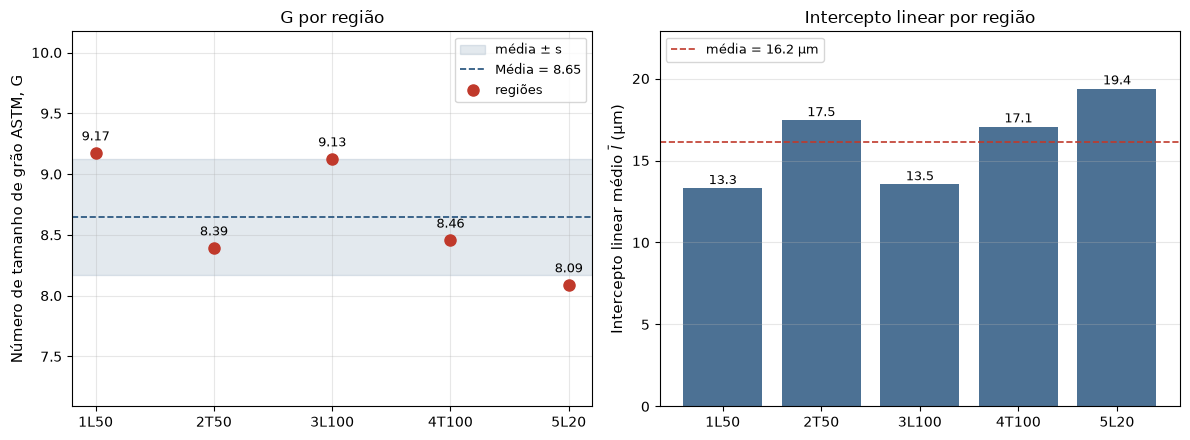

In [85]:
import re
# Rótulo curto a partir do nome do arquivo: "1 - Longitudinal 50X" -> "1L50"
rotulos = [re.sub(r"^(\d+)\s*-\s*(\w)\w*\s+(\d+)X$", r"\1\2\3", os.path.splitext(f)[0])
           for f in FOTOS]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))
pos = np.arange(1, n_reg + 1)

# --- G por região ---
ax1.axhspan(G_media - G_desvio, G_media + G_desvio, color="#1f4e79", alpha=0.12, label="média ± s")
ax1.axhline(G_media, color="#1f4e79", ls="--", lw=1.2, label=f"Média = {G_media:.2f}")
ax1.plot(pos, G, "o", color="#c0392b", ms=8, label="regiões")
for p, g in zip(pos, G):
    ax1.annotate(f"{g:.2f}", (p, g), xytext=(0, 9), textcoords="offset points", ha="center", fontsize=9)
ax1.set_xticks(pos, rotulos)
ax1.set_ylabel("Número de tamanho de grão ASTM, G", fontsize=11)
ax1.set_title("G por região", fontsize=12)
ax1.set_ylim(G.min() - 1, G.max() + 1)
ax1.grid(alpha=0.3); ax1.legend(fontsize=9)

# --- intercepto linear médio por região ---
ax2.bar(pos, l * 1000, color="#1f4e79", alpha=0.8)
ax2.axhline(l_media * 1000, color="#c0392b", ls="--", lw=1.2, label=f"média = {l_media*1000:.1f} µm")
for p, v in zip(pos, l * 1000):
    ax2.annotate(f"{v:.1f}", (p, v), xytext=(0, 3), textcoords="offset points", ha="center", fontsize=9)
ax2.set_xticks(pos, rotulos)
ax2.set_ylabel(r"Intercepto linear médio $\bar{l}$ (µm)", fontsize=11)
ax2.set_title("Intercepto linear por região", fontsize=12)
ax2.set_ylim(0, l.max() * 1000 * 1.18)
ax2.grid(alpha=0.3, axis="y"); ax2.legend(fontsize=9, loc="upper left")

fig.tight_layout()
fig.savefig("tamanho_de_grao_regioes.png", dpi=300)   # figura para o relatório
plt.show()

## 10. Interpretação do resultado

### Escala ASTM

A tabela abaixo situa o resultado na escala ASTM, calculando $\bar{l}$ e a área média de grão para alguns valores inteiros de G. Lembre que **G maior = grão menor**: de G = 5 para G = 9 o intercepto cai a cerca de 1/4.

### Relação com as propriedades mecânicas

Pela equação de Hall-Petch, $\sigma_e = \sigma_0 + k_e d^{-1/2}$, reduzir o tamanho de grão aumenta o limite de escoamento. Como $\bar{l}$ é proporcional ao tamanho de grão, a razão entre os limites de escoamento de duas condições do mesmo material depende de $\bar{l}^{-1/2}$. Por exemplo, reduzir $\bar{l}$ à metade multiplica a parcela $k_e d^{-1/2}$ por $\sqrt{2} \approx 1{,}41$. O refino de grão é o único mecanismo de endurecimento que aumenta a resistência **sem** reduzir a tenacidade, o que explica a importância do controle do tamanho de grão em aços estruturais de baixo carbono como o 1010.

### Pontos para a discussão no relatório

- **Dispersão entre regiões:** o tamanho de grão varia ao longo da amostra (por exemplo, entre a borda e o centro de uma peça laminada). A dispersão medida inclui essa variação real e o erro de contagem.
- **Aumentos diferentes entre as fotos:** nas fotos de 1000× o círculo de 125 µm cruza poucos grãos, então cada erro de ±1 na contagem pesa muito mais que na foto de 200×. A ASTM E112 recomenda escolher o aumento de modo que cada linha de teste cruze dezenas de grãos. Comparem a dispersão entre as fotos de mesmo aumento e entre aumentos diferentes.
- **Fontes de erro:** contornos pouco revelados pelo ataque (grãos "fundidos" na contagem, N menor e G menor), riscos de lixamento confundidos com contornos (N maior), contagem de pontos triplos, aumento real da foto diferente do nominal (seção 3).
- **Representatividade:** a ASTM E112 recomenda escolher os campos sem preferência e medir campos suficientes para que a %RA fique abaixo de 10 % (seção 8).
- **Microestrutura bifásica:** a perlita presente no 1010 foi contada junto com a ferrita. Para medir só o grão ferrítico, a norma tem procedimentos próprios (ASTM E1181), que estão fora do escopo desta prática.

In [82]:
# Escala de referência: l e área média de grão para G inteiros (inverso das eqs. 3 e 1)
G_ref = np.arange(3, 12)
l_ref = 10 ** (-(G_ref + 3.288) / 6.644)            # isola l na eq. (3)
A_ref = 1 / (15.50 * 2 ** (G_ref - 1)) * 1e6        # área média (µm²)
tabela_escala = pd.DataFrame({"l (µm)": (l_ref * 1000).round(1),
                       "Área média de grão (µm²)": A_ref.round(0).astype(int)},
                      index=pd.Index(G_ref, name="G"))

# Destaca a linha do G inteiro mais próximo do resultado
G_prox = int(round(G_media))
print(f"Resultado: G = {G_media:.2f} -> mais próximo de G = {G_prox} na escala ASTM")
tabela_escala.style.apply(lambda r: ["background-color: #ffe9a8" if r.name == G_prox else "" for _ in r], axis=1)

Resultado: G = 8.65 -> mais próximo de G = 9 na escala ASTM


,l (µm),Área média de grão (µm²)
G,,
3,113.100000,16129
4,80.000000,8065
5,56.600000,4032
6,40.000000,2016
7,28.300000,1008
8,20.000000,504
9,14.100000,252
10,10.000000,126
11,7.100000,63


## 11. Resumo dos resultados

In [83]:
resumo_final = pd.DataFrame({"Resultado": [
    "Aço carbono 1010, atacado com Nital 3 %",
    "Intercepto circular, calibrado pela barra de escala de cada foto",
    ", ".join(f"{d} µm ({m}×)" for d, m in zip(D_REAL_UM, AUMENTO_NOMINAL)),
    ", ".join(f"{v:g}" for v in N),
    f"{N_L.min():.2f} a {N_L.max():.2f} mm⁻¹",
    f"{l_media*1000:.2f} ± {l_desvio*1000:.2f} µm",
    f"{G_media:.2f} ± {G_desvio:.2f}",
    f"± {G_ic:.2f} (t = {t95:.3f})",
    f"{RA:.1f} %",
    f"{G_de_l_media:.2f}",
    f"{G_global:.2f}",
]}, index=[
    "Material",
    "Método",
    "Círculos (diâmetro real e aumento)",
    "Contagens N",
    "N_L (faixa)",
    "Intercepto linear médio l (média ± s)",
    "Tamanho de grão ASTM G (média ± s)",
    "IC 95 % de G",
    "Precisão relativa %RA (sobre l)",
    "G a partir de l médio (ASTM E112)",
    "G global (ΣN / ΣL)",
])
display(resumo_final)

# Exporta as tabelas no padrão brasileiro (abrem direto no Excel)
tabela.to_csv("resultados_tamanho_de_grao.csv", sep=";", decimal=",", encoding="utf-8-sig")
tabela_setores.to_csv("contagem_por_setor.csv", sep=";", decimal=",", encoding="utf-8-sig")
print("Tabelas salvas em 'resultados_tamanho_de_grao.csv' e 'contagem_por_setor.csv'")

,Resultado
Material,"Aço carbono 1010, atacado com Nital 3 %"
Método,"Intercepto circular, calibrado pela barra de e..."
Círculos (diâmetro real e aumento),"250 µm (500×), 250 µm (500×), 125 µm (1000×), ..."
Contagens N,"59, 45, 29, 23, 81"
N_L (faixa),51.57 a 75.12 mm⁻¹
Intercepto linear médio l (média ± s),16.15 ± 2.64 µm
Tamanho de grão ASTM G (média ± s),8.65 ± 0.48
IC 95 % de G,± 0.60 (t = 2.776)
Precisão relativa %RA (sobre l),20.3 %
G a partir de l médio (ASTM E112),8.62


Tabelas salvas em 'resultados_tamanho_de_grao.csv' e 'contagem_por_setor.csv'
